In [1]:
import numpy as np
import networkx as nx
import pygsp as gsp
from graph_coarsening.coarsening_utils import coarsen
from diversity_curves.spectral_pool import loukas_pool

/home/limbeckkat/Code/diversity_curves/diversity_curves/spectral_pool.py:33: FutureWarning: In the future `np.bool` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, _name):


In [2]:
G = nx.karate_club_graph()
print(f"Input: {type(G)}, nodes={G.number_of_nodes()}, edges={G.number_of_edges()}")

k = 11
G_pooled, assignment = loukas_pool(G, k=k, method="variation_neighborhood")

print(f"Output: {type(G_pooled)}, nodes={G_pooled.number_of_nodes()}, "
    f"edges={G_pooled.number_of_edges()}")
for c in G_pooled.nodes():
    print(f"  supernode {c}: {G_pooled.nodes[c]}")
for u, v, d in G_pooled.edges(data=True):
    print(f"  edge ({u}, {v}) weight={d['weight']:.2f}")



Input: <class 'networkx.classes.graph.Graph'>, nodes=34, edges=78
Output: <class 'networkx.classes.graph.Graph'>, nodes=11, edges=16
  supernode 0: {'members': [0, 1, 2, 3, 7], 'size': 5}
  supernode 1: {'members': [4], 'size': 1}
  supernode 2: {'members': [5, 6, 16], 'size': 3}
  supernode 3: {'members': [8, 9, 13, 14, 18, 19, 20, 22, 23, 26, 28, 29, 30], 'size': 13}
  supernode 4: {'members': [10], 'size': 1}
  supernode 5: {'members': [11], 'size': 1}
  supernode 6: {'members': [12], 'size': 1}
  supernode 7: {'members': [15, 32, 33], 'size': 3}
  supernode 8: {'members': [17], 'size': 1}
  supernode 9: {'members': [21], 'size': 1}
  supernode 10: {'members': [24, 25, 27, 31], 'size': 4}
  edge (0, 1) weight=3.00
  edge (0, 2) weight=6.00
  edge (0, 3) weight=30.00
  edge (0, 4) weight=2.00
  edge (0, 5) weight=3.00
  edge (0, 6) weight=4.00
  edge (0, 7) weight=2.00
  edge (0, 8) weight=3.00
  edge (0, 9) weight=4.00
  edge (0, 10) weight=4.00
  edge (1, 2) weight=2.00
  edge (1, 

In [3]:
import matplotlib.pyplot as plt
import networkx as nx


def plot_pooling(G: nx.Graph, G_pooled: nx.Graph, assignment: dict,
                  seed: int = 0, savepath: str = None):
    """
    Side-by-side plot: original graph colored by cluster assignment, and
    the pooled graph with node size ~ cluster size and edge width ~ weight.
    """
    k = G_pooled.number_of_nodes()
    cmap = plt.get_cmap("tab20", k)

    fig, axes = plt.subplots(1, 2, figsize=(13, 6))

    # --- Left: original graph, nodes colored by cluster ---
    pos = nx.spring_layout(G, seed=seed)
    #node_colors = [cmap(assignment[n]) for n in G.nodes()]
    nx.draw_networkx_edges(G, pos, ax=axes[0], alpha=0.4)
    nx.draw_networkx_nodes(G, pos, ax=axes[0], #node_color=node_colors,
                            node_size=120, edgecolors="black", linewidths=0.5)
    axes[0].set_title(f"Original graph (n={G.number_of_nodes()}), "
                       f"colored by cluster")
    axes[0].axis("off")

    # --- Right: pooled graph ---
    pos_pooled = nx.spring_layout(G_pooled, seed=seed)
    sizes = [200 + 300 * G_pooled.nodes[c]["size"] for c in G_pooled.nodes()]
    #colors = [cmap(c) for c in G_pooled.nodes()]
    weights = [G_pooled[u][v]["weight"] for u, v in G_pooled.edges()]
    max_w = max(weights) if weights else 1.0
    widths = [1 + 4 * (w / max_w) for w in weights]

    nx.draw_networkx_edges(G_pooled, pos_pooled, ax=axes[1], width=widths,
                            alpha=0.6)
    nx.draw_networkx_nodes(G_pooled, pos_pooled, ax=axes[1],
                            #node_color=colors, 
                            # node_size=sizes,
                            edgecolors="black", linewidths=0.8)
    nx.draw_networkx_labels(G_pooled, pos_pooled, ax=axes[1],
                             labels={c: str(G_pooled.nodes[c]["size"])
                                     for c in G_pooled.nodes()},
                             font_size=9, font_color="white",
                             font_weight="bold")
    axes[1].set_title(f"Pooled graph (k={k}), node size ~ cluster size, "
                       f"label = # merged nodes")
    axes[1].axis("off")

    fig.tight_layout()
    if savepath:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig

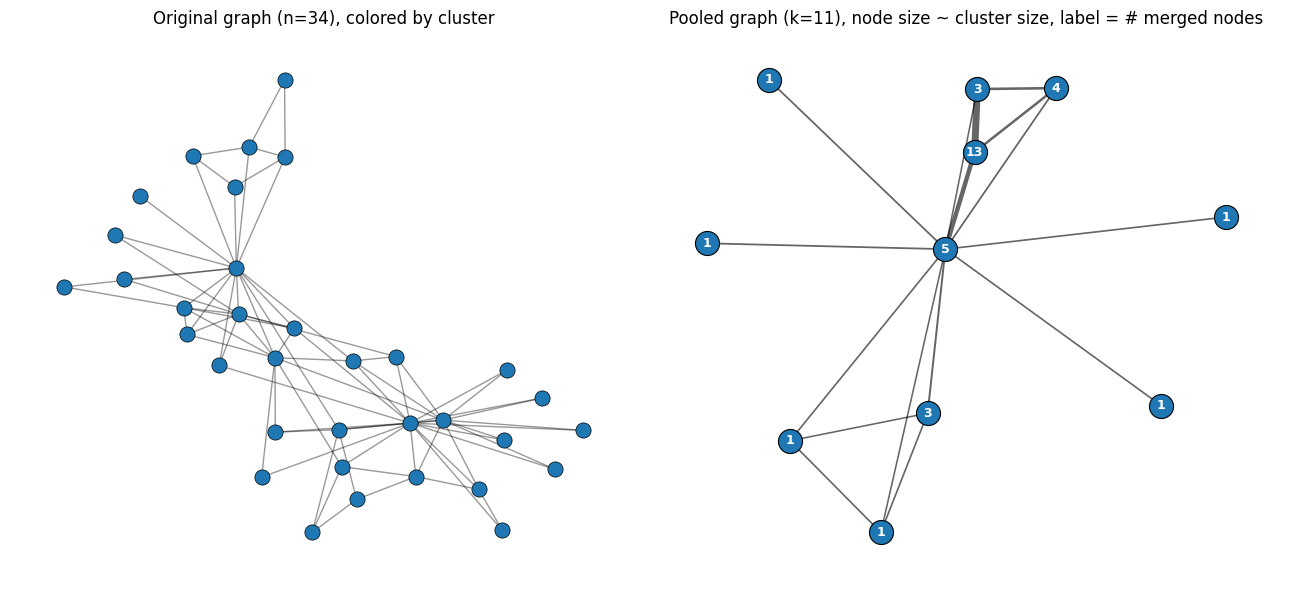

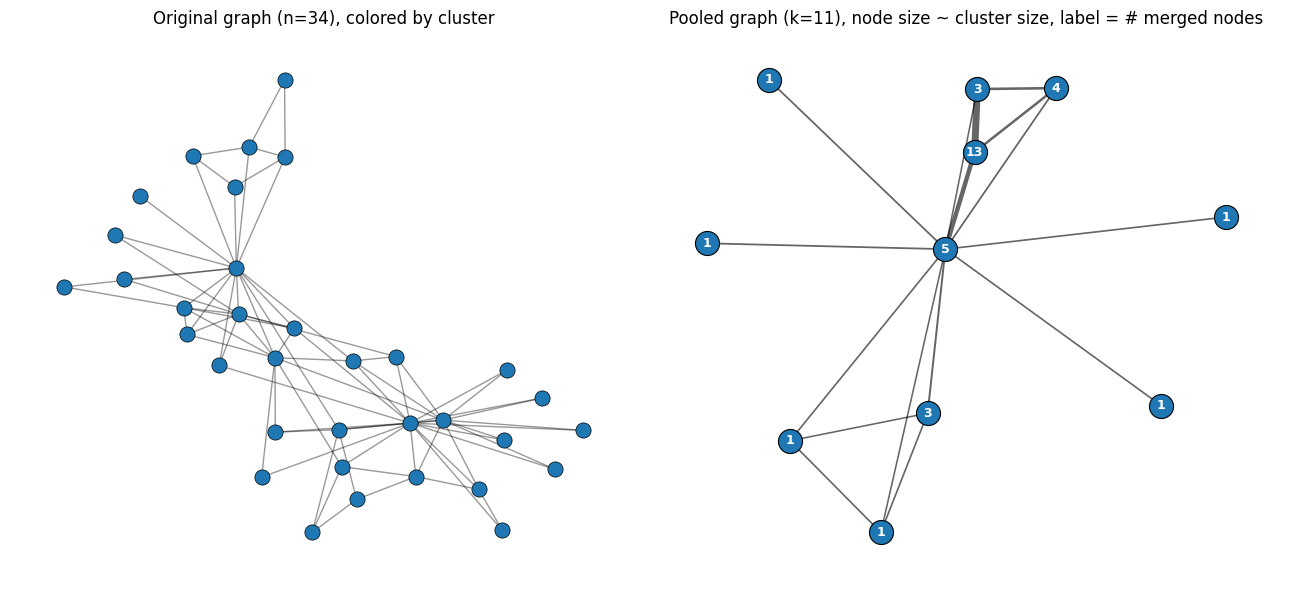

In [4]:
plot_pooling(G, G_pooled, assignment, seed=1)

In [5]:
from diversity_curves.coarsen import coarsened_diversity
from diversity_curves.spectral_pool import loukas_pool
from diversity_curves.process import get_funs_df, get_mag_graphs

In [6]:
from magnipy.magnitude.distances import get_dist
def dist_fn(G):
    return get_dist(G=G, X=None, X2=None, metric="shortest_path_distance", mode="structure")

In [19]:
compute_at_cardinality = [r for r in range(1, G.number_of_nodes()+1)]
all_spreads, weights_lists = get_mag_graphs(
    [G],
    dist_fn,
    ts=[1],
    n_repeats=3,
    mode="structure",
    compute_at_cardinality=compute_at_cardinality,
)
#weight_diffs = get_weight_diffs(weights_lists)
#funs_diffs = get_funs_diff(all_spreads)
mag_funs = get_funs_df(all_spreads)
#num_cols = mag_funs.select_dtypes(include=[np.number]).columns
#mag_funs[num_cols] = mag_funs[num_cols].interpolate(method="linear", axis=0, limit_direction="both")
mag_funs

index,1,2,3,4,5,6,7,8,9,10,...,25,26,27,28,29,30,31,32,33,34
graph,,,,,,,,,,,,,,,,,,,,,
0,1,1.462117,1.847183,2.247214,2.525696,2.754755,3.052232,3.239011,3.447095,3.557988,...,5.691025,5.814667,6.000953,6.078182,6.225876,6.32878,6.447158,6.612763,6.826081,6.806097


In [20]:
compute_at_cardinality = [r for r in range(1, G.number_of_nodes()+1)]
all_spreads, weights_lists = get_mag_graphs(
    [G],
    dist_fn,
    ts=[1],
    n_repeats=3,
    mode="structure",
    compute_at_cardinality=compute_at_cardinality,
    coarsening = "spectral"
)
#weight_diffs = get_weight_diffs(weights_lists)
#funs_diffs = get_funs_diff(all_spreads)
mag_funs_spectral = get_funs_df(all_spreads)
mag_funs_spectral

k=1 did not work!
k=2 did not work!


/home/limbeckkat/Code/diversity_curves/.venv/lib/python3.10/site-packages/graph_coarsening/coarsening_utils.py:101: RuntimeWarning: invalid value encountered in power
  dinvsqrt = d ** (-1 / 2)


k=8 did not work!
k=9 did not work!
k=10 did not work!
k=12 did not work!
k=15 did not work!
k=22 did not work!
k=32 did not work!
k=33 did not work!
k=1 did not work!
k=2 did not work!
k=8 did not work!
k=9 did not work!
k=10 did not work!
k=12 did not work!
k=15 did not work!
k=22 did not work!
k=32 did not work!
k=33 did not work!
k=1 did not work!
k=2 did not work!
k=8 did not work!
k=9 did not work!
k=10 did not work!
k=12 did not work!
k=15 did not work!
k=22 did not work!
k=32 did not work!
k=33 did not work!


index,1,3,4,5,6,7,11,13,14,16,...,23,24,25,26,27,28,29,30,31,34
graph,,,,,,,,,,,,,,,,,,,,,
0,1,1.906599,2.019627,2.411773,2.857319,2.770393,3.72716,4.122649,4.23829,4.93563,...,5.554084,5.903017,5.903822,5.721059,5.988628,6.027099,6.146262,6.265351,6.407258,6.806097


In [21]:
mag_funs_spectral

index,1,3,4,5,6,7,11,13,14,16,...,23,24,25,26,27,28,29,30,31,34
graph,,,,,,,,,,,,,,,,,,,,,
0,1,1.906599,2.019627,2.411773,2.857319,2.770393,3.72716,4.122649,4.23829,4.93563,...,5.554084,5.903017,5.903822,5.721059,5.988628,6.027099,6.146262,6.265351,6.407258,6.806097


In [22]:
import pandas as pd
df_all_copy = pd.merge(mag_funs, mag_funs_spectral, how="outer")
df_all_copy.index = ["edge_pool", "loukas_pool"]
num_cols = df_all_copy.select_dtypes(include=[np.number]).columns
df_all_copy[num_cols] = df_all_copy[num_cols].interpolate(method="linear", axis=0, limit_direction="both")
df_all_copy

index,1,2,3,4,5,6,7,8,9,10,...,25,26,27,28,29,30,31,32,33,34
edge_pool,1,1.462117,1.847183,2.247214,2.525696,2.754755,3.052232,3.239011,3.447095,3.557988,...,5.691025,5.814667,6.000953,6.078182,6.225876,6.328780,6.447158,6.612763,6.826081,6.806097
loukas_pool,1,1.462117,1.906599,2.019627,2.411773,2.857319,2.770393,3.239011,3.447095,3.557988,...,5.903822,5.721059,5.988628,6.027099,6.146262,6.265351,6.407258,6.612763,6.826081,6.806097


<Axes: xlabel='index'>

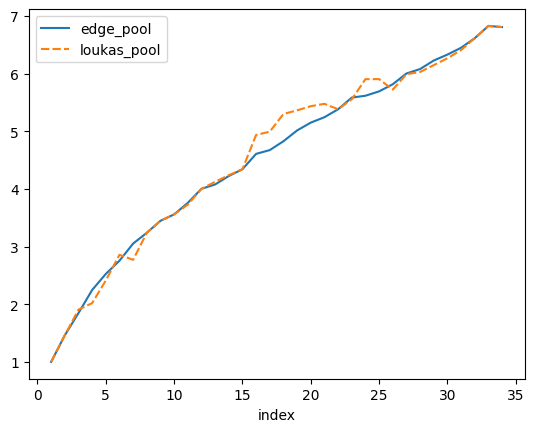

In [23]:
import seaborn as sns
sns.lineplot(df_all_copy.T)